# League of Legends: Random Forest and Gradient Boosting

Owner: Yejune. Run notebooks 01–03 first to generate `split_ids.csv` and Isaac's reference results.

This notebook compares **Random Forest** and **HistGradientBoostingClassifier** on the same training matches, feature definitions, and five grouped folds as notebook 03. It starts at minute 14, then evaluates minutes 10, 18, and 20.

- Feature construction: `src.features.build_features()`.
- Selection and scoring: `src.evaluation.tune()` and `cv_scores()`; **minimum CV log loss** selects the setting.
- Default comparison: **Notebook 01 features vs. All engineered**. The full feature ablation is optional.
- Only training matches enter model fitting or scoring. No held-out test predictions or metrics are computed here.
- CV results support model selection; final test evaluation follows after all four model families have frozen configurations.

## 1. Setup and experiment settings

The default grids contain 16 settings per ensemble. With two feature sets, four minutes, and five folds, this means **1,280 ensemble CV fits**, plus refits and baseline scoring. Start by running through the minute-14 section if you want to inspect those results first.

Set `FULL_ABLATION = True` to include all distinct feature sets from notebook 03. Completed experiments are reused only when their data, features, model settings, grids, shared source, and package versions match. Set `FORCE_RECOMPUTE = True` to rerun them.

In [1]:
import ast
import hashlib
import json
import platform
import re
import sys
from importlib.metadata import version
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display
from joblib import parallel_config
from sklearn.ensemble import HistGradientBoostingClassifier, RandomForestClassifier
from sklearn.model_selection import ParameterGrid
from threadpoolctl import threadpool_limits

root = next(
    (p for p in [Path.cwd(), *Path.cwd().parents]
     if (p / "src" / "features.py").is_file()
     and (p / "data" / "raw" / "lol_ranked_games.csv").is_file()),
    None,
)
if root is None:
    raise FileNotFoundError("Open this notebook inside the project repository.")
if str(root) not in sys.path:
    sys.path.insert(0, str(root))

from src.evaluation import METRIC_COLS, SEED, GoldLeadRule, cv, cv_scores, summarize, tune
from src.features import NOTEBOOK01_FEATURES, OBJECTIVE_FEATURES, TRAJECTORY_FEATURES, build_features

processed_dir = root / "data" / "processed"
source_report_dir = root / "reports"
report_dir = root / "reports"
figure_dir = report_dir / "figures"
search_dir = report_dir / "ensemble_searches"
for directory in (report_dir, figure_dir, search_dir):
    directory.mkdir(parents=True, exist_ok=True)

MINUTES = [14, 10, 18, 20]  # minute 14 first; it is reused in the across-minute table
FULL_ABLATION = False
FORCE_RECOMPUTE = False

RF_GRID = {
    "n_estimators": [200, 400],
    "max_depth": [8, None],
    "min_samples_leaf": [5, 25],
    "max_features": ["sqrt", 0.5],
}
HGB_GRID = {
    "learning_rate": [0.05, 0.1],
    "max_iter": [200],
    "max_leaf_nodes": [15, 31],
    "min_samples_leaf": [20, 100],
    "l2_regularization": [0.0, 1.0],
}

# The shared helpers parallelize CV. Keep individual forests single-threaded.
# Disable HGB early stopping so every CV training fold supplies the fitted data;
# max_iter is explicit and validation folds are used only by shared grouped CV.
MODEL_SPECS = {
    "Random forest": (RandomForestClassifier(random_state=SEED, n_jobs=1), RF_GRID),
    "HistGradientBoosting": (
        HistGradientBoostingClassifier(random_state=SEED, early_stopping=False), HGB_GRID
    ),
}

print("Python:", platform.python_version(), "| scikit-learn:", version("scikit-learn"))
print("Settings per model:", {name: len(ParameterGrid(grid))
                              for name, (_, grid) in MODEL_SPECS.items()})

Python: 3.13.3 | scikit-learn: 1.9.1
Settings per model: {'Random forest': 16, 'HistGradientBoosting': 16}


## 2. Load the existing split and reproduce the feature groups

`build_features()` returns eligible matches from both split assignments, so we filter explicitly to training IDs. Match order is preserved to reproduce notebook 03's fold membership.

At minute 14 the default sets have 58 and 80 columns. At minute 10 they have 56 and 70 columns: trajectory features do not exist. Notebook 03 drops the duplicate `All engineered` label at minute 10; its equivalent is called `+ objective`. We preserve that correspondence when loading Isaac's results.

In [2]:
split_path = processed_dir / "split_ids.csv"
if not split_path.is_file():
    raise FileNotFoundError(f"Missing {split_path}. Run notebook 01 first.")

raw_path = root / "data" / "raw" / "lol_ranked_games.csv"
raw = pd.read_csv(raw_path)
split_ids = pd.read_csv(split_path)
assert split_ids["gameId"].is_unique, "Duplicate match assignments."
assert set(split_ids["split"]) == {"train", "test"}, "Unexpected split labels."
assert not raw.duplicated(["gameId", "frame"]).any(), "Duplicate snapshots."
assert raw["hasWon"].isin([0, 1]).all(), "Invalid outcome labels."
assert raw.groupby("gameId")["hasWon"].nunique().eq(1).all(), "Inconsistent match outcomes."
assert set(raw["gameId"]) == set(split_ids["gameId"]), "Dataset and split IDs differ."

train_ids = set(split_ids.loc[split_ids["split"].eq("train"), "gameId"])
test_ids = set(split_ids.loc[split_ids["split"].eq("test"), "gameId"])
assert train_ids.isdisjoint(test_ids)
print(f"Training match IDs: {len(train_ids):,}; reserved match IDs: {len(test_ids):,}")

def unique(cols):
    return list(dict.fromkeys(cols))

def feature_sets_for(groups, minute):
    """Same definition and duplicate removal as notebook 03, cell 13."""
    raw_cols = groups["raw"]
    nb01_cols = [c for c in NOTEBOOK01_FEATURES if minute >= 14 or c not in TRAJECTORY_FEATURES]
    new = unique(OBJECTIVE_FEATURES + groups["trajectory"])
    candidates = {
        "Notebook 01 features": unique(raw_cols + nb01_cols),
        "+ objective": unique(raw_cols + nb01_cols + OBJECTIVE_FEATURES),
        "+ trajectory": unique(raw_cols + nb01_cols + groups["trajectory"]),
        "All engineered": unique(raw_cols + new),
        "Compact engineered": unique(["goldDiff", "expDiff", "champLevelDiff"] + new),
    }
    sets, seen = {}, []
    for name, cols in candidates.items():
        if set(cols) not in seen:
            sets[name] = cols
            seen.append(set(cols))
    return sets

def selected_feature_sets(groups, minute):
    sets = feature_sets_for(groups, minute)
    if FULL_ABLATION:
        return sets
    expanded = sets["All engineered"] if "All engineered" in sets else sets["+ objective"]
    return {"Notebook 01 features": sets["Notebook 01 features"], "All engineered": expanded}

def isaac_feature_label(name, minute):
    return "+ objective" if minute == 10 and name == "All engineered" else name

training_tables = {}
def training_data_for(minute):
    if minute not in training_tables:
        table, groups = build_features(raw, minute)
        data = table.loc[table["gameId"].isin(train_ids)].reset_index(drop=True)
        assert data["gameId"].is_unique
        assert not data["gameId"].isin(test_ids).any()
        assert data["hasWon"].nunique() == 2
        sets = selected_feature_sets(groups, minute)
        forbidden = {"gameId", "hasWon", "gameDuration", "frame", "split"}
        for name, cols in sets.items():
            assert len(cols) == len(set(cols)), name
            assert not forbidden.intersection(cols), name
            assert np.isfinite(data[cols].to_numpy()).all(), name
        training_tables[minute] = (data, sets)
    return training_tables[minute]

train14, sets14 = training_data_for(14)
display(pd.DataFrame([
    {"features": name, "n_features": len(cols), "training_matches": len(train14)}
    for name, cols in sets14.items()
]))

Training match IDs: 19,929; reserved match IDs: 4,983


,features,n_features,training_matches
0,Notebook 01 features,58,19723
1,All engineered,80,19723


## 3. Run and save grouped-CV searches

Each experiment saves its selected per-fold scores and full search table immediately. A content fingerprint prevents reuse after the data, feature list/order, estimator, grid, CV folds, shared modules, or relevant software versions change. Only completed searches are cached; an interrupted search restarts that experiment.

Saved fold scores come from the selected setting in `tune()`. Running `cv_scores()` again on the winner would repeat the same folds, not provide an independent evaluation. We use `cv_scores()` for the fixed gold-lead baseline instead.

In [3]:
def json_default(value):
    if isinstance(value, np.ndarray):
        return value.tolist()
    if isinstance(value, np.generic):
        return value.item()
    raise TypeError(f"Cannot encode {type(value).__name__}")

def json_text(value):
    return json.dumps(value, sort_keys=True, default=json_default, allow_nan=False)

def file_sha256(path):
    digest = hashlib.sha256()
    with Path(path).open("rb") as stream:
        for block in iter(lambda: stream.read(1024 * 1024), b""):
            digest.update(block)
    return digest.hexdigest()

PROVENANCE = {
    "raw_sha256": file_sha256(raw_path),
    "split_sha256": file_sha256(split_path),
    "features_source_sha256": file_sha256(root / "src" / "features.py"),
    "evaluation_source_sha256": file_sha256(root / "src" / "evaluation.py"),
    "versions": {name: version(name) for name in ("numpy", "pandas", "scikit-learn", "joblib")},
    "python": platform.python_version(),
    "seed": SEED,
}

def write_results(frame, path):
    out = frame.copy()
    for column in out.columns:
        out[column] = out[column].map(
            lambda value: json_text(value) if isinstance(value, (dict, list, tuple, np.ndarray)) else value
        )
    out.to_csv(path, index=False)

def run_experiment(model_name, model, grid, data, cols, feature_name, minute):
    assert data["gameId"].isin(train_ids).all()
    assert not data["gameId"].isin(test_ids).any()
    signature = {
        "provenance": PROVENANCE,
        "minute": minute,
        "training_row_hash": hashlib.sha256(
            pd.util.hash_pandas_object(data[["gameId", "hasWon"]], index=False).values.tobytes()
        ).hexdigest(),
        "columns": cols,
        "estimator": f"{type(model).__module__}.{type(model).__name__}",
        "base_params": model.get_params(),
        "grid": grid,
        "cv": {"class": type(cv).__name__, **cv.__dict__},
    }
    fingerprint = hashlib.sha256(json_text(signature).encode()).hexdigest()
    slug = re.sub(r"[^a-z0-9]+", "_", f"{model_name}_{feature_name}".lower()).strip("_")
    stem = f"minute{minute}_{slug}_{fingerprint[:12]}"
    cache_path = search_dir / f"{stem}.json"
    if cache_path.is_file() and not FORCE_RECOMPUTE:
        saved = json.loads(cache_path.read_text())
        if saved["fingerprint"] == fingerprint:
            print(f"Reuse: minute {minute}, {model_name}, {feature_name}", flush=True)
            return saved["row"]

    n_settings = 1 if grid is None else len(ParameterGrid(grid))
    print(f"Run: minute {minute}, {model_name}, {feature_name} "
          f"({n_settings} settings × {cv.get_n_splits()} folds)", flush=True)
    started = perf_counter()
    # Shared helpers use n_jobs=-1. Limit native threads inside each CV worker.
    with parallel_config(backend="loky", inner_max_num_threads=1), threadpool_limits(limits=1):
        if grid is None:
            scores = cv_scores(model, data, cols)
            best_params = {}
        else:
            search, scores = tune(model, grid, data, cols)
            best_params = search.best_params_
            pd.DataFrame(search.cv_results_).to_csv(search_dir / f"{stem}_grid.csv", index=False)

    row = summarize(model_name, feature_name, scores, best_params,
                    minute=minute, n_features=len(cols), train_matches=len(data),
                    feature_columns=cols, source="Yejune (04)",
                    elapsed_seconds=perf_counter() - started,
                    fingerprint=fingerprint)
    cache_path.write_text(json.dumps(
        {"fingerprint": fingerprint, "signature": signature, "row": row},
        indent=2, default=json_default, allow_nan=False,
    ) + "\n")
    print(f"Finished: log loss={row['log_loss']:.4f}, accuracy={row['accuracy']:.4f}", flush=True)
    return row

completed_baselines = {}

def run_minute(minute):
    data, sets = training_data_for(minute)
    rows = [run_experiment("Gold-lead rule", GoldLeadRule(), None, data,
                           ["goldDiff"], "sign of goldDiff", minute)]
    completed_baselines[minute] = rows[0]
    for feature_name, cols in sets.items():
        for model_name, (model, grid) in MODEL_SPECS.items():
            rows.append(run_experiment(model_name, model, grid, data, cols, feature_name, minute))
    frame = pd.DataFrame(rows)
    write_results(frame, report_dir / f"ensemble_minute{minute}_results.csv")
    return frame

## 4. Minute-14 ensemble comparison

This is the main experiment. Compare probability quality as well as classification accuracy. More columns do not guarantee an improvement.

In [4]:
minute14_results = run_minute(14)
display(minute14_results[["model", "features", "n_features", "train_matches"]
                         + METRIC_COLS + ["params"]].round(4))

Run: minute 14, Gold-lead rule, sign of goldDiff (1 settings × 5 folds)
Finished: log loss=0.5487, accuracy=0.7622
Run: minute 14, Random forest, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.4735, accuracy=0.7697
Run: minute 14, HistGradientBoosting, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.4747, accuracy=0.7698
Run: minute 14, Random forest, All engineered (16 settings × 5 folds)
Finished: log loss=0.4733, accuracy=0.7682
Run: minute 14, HistGradientBoosting, All engineered (16 settings × 5 folds)
Finished: log loss=0.4753, accuracy=0.7680


,model,features,n_features,train_matches,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
0,Gold-lead rule,sign of goldDiff,1,19723,0.7622,0.0078,0.7622,0.5487,0.1813,{}
1,Random forest,Notebook 01 features,58,19723,0.7697,0.0102,0.8536,0.4735,0.1561,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."
2,HistGradientBoosting,Notebook 01 features,58,19723,0.7698,0.0091,0.8529,0.4747,0.1566,"{'l2_regularization': 1.0, 'learning_rate': 0...."
3,Random forest,All engineered,80,19723,0.7682,0.0089,0.8537,0.4733,0.1561,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
4,HistGradientBoosting,All engineered,80,19723,0.7680,0.0097,0.8525,0.4753,0.1567,"{'l2_regularization': 1.0, 'learning_rate': 0...."


### Compare with Isaac's matching feature sets

Reference rows come from `fe_by_minute.csv`, which includes the same ablation at every minute. The four-feature LR/DT candidates from `fe_minute14_results.csv` are shown separately as additional candidates; they are not substituted for the matching-feature ablation.

In [5]:
def decode_saved(value):
    if not isinstance(value, str):
        return value
    try:
        return json.loads(value)
    except json.JSONDecodeError:
        return ast.literal_eval(value)  # Isaac's CSV uses Python dict/list literals

isaac_path = source_report_dir / "fe_by_minute.csv"
if not isaac_path.is_file():
    raise FileNotFoundError(f"Missing {isaac_path}. Run notebook 03 first.")
isaac_all = pd.read_csv(isaac_path)
for column in ("params", "fold_accuracy", "fold_log_loss"):
    isaac_all[column] = isaac_all[column].map(decode_saved)

def matching_isaac_rows(minutes):
    rows = []
    for minute in minutes:
        data, sets = training_data_for(minute)
        reference_baseline = isaac_all.loc[
            isaac_all["minute"].eq(minute) & isaac_all["model"].eq("Gold-lead rule")
        ]
        if len(reference_baseline) != 1:
            raise ValueError(f"Expected one reference gold-lead baseline at minute {minute}.")
        # Reproducing its per-fold scores checks data/fold compatibility before comparison.
        for metric in ("fold_accuracy", "fold_log_loss"):
            np.testing.assert_allclose(
                completed_baselines[minute][metric], reference_baseline.iloc[0][metric],
                rtol=1e-6, atol=1e-8,
                err_msg=f"Minute {minute}: baseline folds differ from Isaac; check data/split/protocol.",
            )
        for name in sets:
            source_label = isaac_feature_label(name, minute)
            matches = isaac_all.loc[
                isaac_all["minute"].eq(minute)
                & isaac_all["features"].eq(source_label)
                & isaac_all["model"].isin(["Logistic regression", "Decision tree"])
            ].copy()
            if len(matches) != 2:
                raise ValueError(f"Expected two Isaac rows: minute {minute}, {source_label}.")
            if not matches["n_features"].eq(len(sets[name])).all():
                raise ValueError(f"Feature count differs from Isaac: minute {minute}, {name}.")
            matches["isaac_feature_label"] = source_label
            matches["features"] = name
            matches["train_matches"] = len(data)
            matches["source"] = "Isaac (03)"
            rows.append(matches)
    return pd.concat(rows, ignore_index=True)

comparison14 = pd.concat([matching_isaac_rows([14]), minute14_results], ignore_index=True)
write_results(comparison14, report_dir / "ensemble_minute14_comparison.csv")
display(comparison14[["source", "model", "features"] + METRIC_COLS]
        .sort_values("log_loss").round(4))

selected14 = pd.read_csv(source_report_dir / "fe_minute14_results.csv")
selected14 = selected14.loc[selected14["features"].eq("L1-selected")]
print("Additional four-feature candidates from notebook 03:")
display(selected14[["model", "features", "n_features"] + METRIC_COLS + ["params"]].round(4))

,source,model,features,accuracy,accuracy_sd,roc_auc,log_loss,brier
0,Isaac (03),Logistic regression,Notebook 01 features,0.7705,0.0094,0.8549,0.4715,0.1554
2,Isaac (03),Logistic regression,All engineered,0.7697,0.0092,0.8546,0.4717,0.1555
7,Yejune (04),Random forest,All engineered,0.7682,0.0089,0.8537,0.4733,0.1561
5,Yejune (04),Random forest,Notebook 01 features,0.7697,0.0102,0.8536,0.4735,0.1561
6,Yejune (04),HistGradientBoosting,Notebook 01 features,0.7698,0.0091,0.8529,0.4747,0.1566
8,Yejune (04),HistGradientBoosting,All engineered,0.7680,0.0097,0.8525,0.4753,0.1567
1,Isaac (03),Decision tree,Notebook 01 features,0.7642,0.0105,0.8483,0.4817,0.1587
3,Isaac (03),Decision tree,All engineered,0.7658,0.0096,0.8481,0.4824,0.1588
4,Yejune (04),Gold-lead rule,sign of goldDiff,0.7622,0.0078,0.7622,0.5487,0.1813


Additional four-feature candidates from notebook 03:


,model,features,n_features,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
13,Logistic regression,L1-selected,4,0.771,0.0082,0.8555,0.4705,0.1550,{'logisticregression__C': 10}
14,Decision tree,L1-selected,4,0.765,0.0106,0.8482,0.4816,0.1587,"{'max_depth': 6, 'min_samples_leaf': 400}"


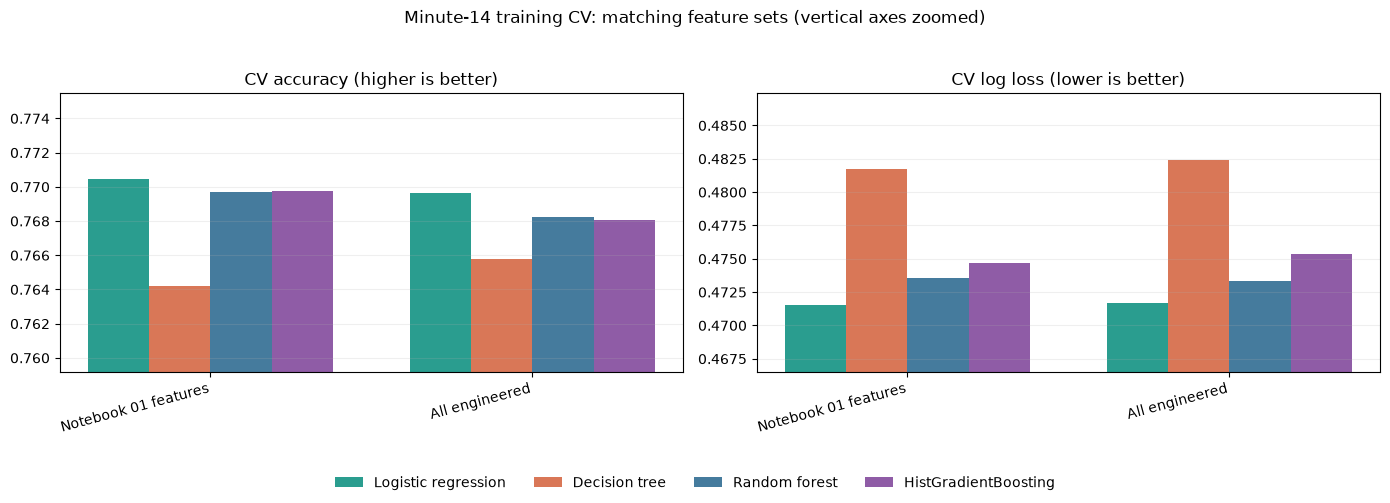

In [6]:
model_colors = {"Logistic regression": "#2a9d8f", "Decision tree": "#d97757",
                "Random forest": "#457b9d", "HistGradientBoosting": "#8f5ca6"}

def plot_minute14_comparison(frame):
    data = frame.loc[frame["model"].isin(model_colors)]
    feature_names = list(dict.fromkeys(data["features"]))
    x = np.arange(len(feature_names))
    width = 0.19
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, metric, title in [(axes[0], "accuracy", "CV accuracy (higher is better)"),
                              (axes[1], "log_loss", "CV log loss (lower is better)")]:
        for j, (model_name, color) in enumerate(model_colors.items()):
            part = data.loc[data["model"].eq(model_name)].set_index("features").reindex(feature_names)
            ax.bar(x + (j - 1.5) * width, part[metric], width, color=color, label=model_name)
        ax.set_xticks(x, feature_names, rotation=15, ha="right")
        ax.set_title(title)
        lo, hi = data[metric].min(), data[metric].max()
        pad = max((hi - lo) * 0.4, 0.005)
        ax.set_ylim(max(0, lo - pad), hi + pad)
        ax.grid(axis="y", alpha=0.2)
    handles, labels = axes[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="lower center", ncol=4, frameon=False)
    fig.suptitle("Minute-14 training CV: matching feature sets (vertical axes zoomed)")
    fig.tight_layout(rect=[0, 0.10, 1, 0.95])
    fig.savefig(figure_dir / "ensemble_minute14_comparison.png", dpi=180, bbox_inches="tight")
    plt.show()

plot_minute14_comparison(comparison14)

## 5. Repeat at minutes 10, 18, and 20

All experiments use the original match assignments. Later minutes have fewer eligible matches because games have ended; changes in performance combine additional information with changes in the cohort. Minute 14 is reused rather than tuned twice.

In [7]:
minute_frames = {14: minute14_results}
for minute in MINUTES:
    if minute != 14:
        minute_frames[minute] = run_minute(minute)

ensemble_by_minute = pd.concat([minute_frames[t] for t in sorted(minute_frames)], ignore_index=True)
write_results(ensemble_by_minute, report_dir / "ensemble_by_minute.csv")
comparison_by_minute = pd.concat(
    [matching_isaac_rows(sorted(minute_frames)), ensemble_by_minute], ignore_index=True
)
write_results(comparison_by_minute, report_dir / "ensemble_all_models_by_minute.csv")

print("Eligible training cohorts:")
display(ensemble_by_minute[["minute", "train_matches"]].drop_duplicates().set_index("minute"))
for metric in ("accuracy", "roc_auc", "log_loss", "brier"):
    print(metric)
    display(comparison_by_minute.loc[comparison_by_minute["model"].isin(model_colors)]
            .pivot(index=["model", "features"], columns="minute", values=metric).round(4))

Run: minute 10, Gold-lead rule, sign of goldDiff (1 settings × 5 folds)
Finished: log loss=0.5985, accuracy=0.7141
Run: minute 10, Random forest, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.5410, accuracy=0.7200
Run: minute 10, HistGradientBoosting, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.5429, accuracy=0.7217
Run: minute 10, Random forest, All engineered (16 settings × 5 folds)
Finished: log loss=0.5412, accuracy=0.7208
Run: minute 10, HistGradientBoosting, All engineered (16 settings × 5 folds)
Finished: log loss=0.5432, accuracy=0.7192
Run: minute 18, Gold-lead rule, sign of goldDiff (1 settings × 5 folds)
Finished: log loss=0.5181, accuracy=0.7869
Run: minute 18, Random forest, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.4275, accuracy=0.7960
Run: minute 18, HistGradientBoosting, Notebook 01 features (16 settings × 5 folds)
Finished: log loss=0.4294, accuracy=0.7954
Run: minute 18, Random forest, All engineered (

,train_matches
minute,
10,19912
14,19723
18,18565
20,17738


accuracy


minute                                         10      14      18      20
model                features                                            
Decision tree        All engineered        0.7189  0.7658  0.7900  0.7994
                     Notebook 01 features  0.7189  0.7642  0.7908  0.7994
HistGradientBoosting All engineered        0.7192  0.7680  0.7980  0.8067
                     Notebook 01 features  0.7217  0.7698  0.7954  0.8074
Logistic regression  All engineered        0.7232  0.7697  0.7998  0.8082
                     Notebook 01 features  0.7226  0.7705  0.7995  0.8101
Random forest        All engineered        0.7208  0.7682  0.7989  0.8068
                     Notebook 01 features  0.7200  0.7697  0.7960  0.8064

roc_auc


minute                                         10      14      18      20
model                features                                            
Decision tree        All engineered        0.7965  0.8481  0.8728  0.8852
                     Notebook 01 features  0.7968  0.8483  0.8736  0.8875
HistGradientBoosting All engineered        0.7987  0.8525  0.8822  0.8931
                     Notebook 01 features  0.7991  0.8529  0.8824  0.8931
Logistic regression  All engineered        0.8025  0.8546  0.8847  0.8957
                     Notebook 01 features  0.8024  0.8549  0.8846  0.8955
Random forest        All engineered        0.8001  0.8537  0.8834  0.8941
                     Notebook 01 features  0.8006  0.8536  0.8832  0.8940

log_loss


minute                                         10      14      18      20
model                features                                            
Decision tree        All engineered        0.5454  0.4824  0.4430  0.4243
                     Notebook 01 features  0.5449  0.4817  0.4415  0.4239
HistGradientBoosting All engineered        0.5432  0.4753  0.4296  0.4117
                     Notebook 01 features  0.5429  0.4747  0.4294  0.4117
Logistic regression  All engineered        0.5379  0.4717  0.4253  0.4064
                     Notebook 01 features  0.5381  0.4715  0.4254  0.4067
Random forest        All engineered        0.5412  0.4733  0.4277  0.4097
                     Notebook 01 features  0.5410  0.4735  0.4275  0.4100

brier


minute                                         10      14      18      20
model                features                                            
Decision tree        All engineered        0.1839  0.1588  0.1442  0.1368
                     Notebook 01 features  0.1838  0.1587  0.1436  0.1362
HistGradientBoosting All engineered        0.1831  0.1567  0.1396  0.1328
                     Notebook 01 features  0.1829  0.1566  0.1395  0.1327
Logistic regression  All engineered        0.1813  0.1555  0.1381  0.1312
                     Notebook 01 features  0.1814  0.1554  0.1381  0.1313
Random forest        All engineered        0.1824  0.1561  0.1388  0.1322
                     Notebook 01 features  0.1822  0.1561  0.1389  0.1323

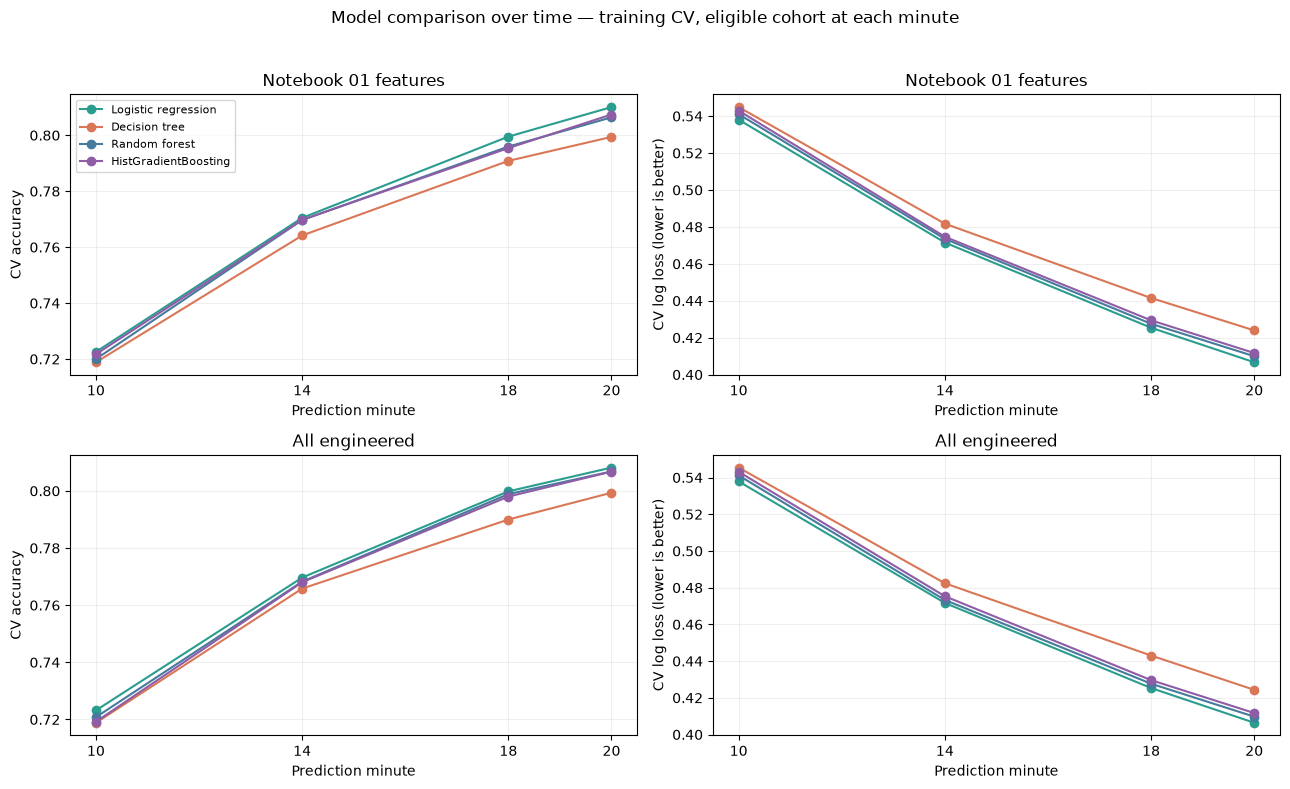

In [8]:
plot_data = comparison_by_minute.loc[comparison_by_minute["model"].isin(model_colors)]
features_to_plot = list(dict.fromkeys(plot_data["features"]))
fig, axes = plt.subplots(len(features_to_plot), 2,
                         figsize=(13, 4 * len(features_to_plot)), squeeze=False)
for row, name in enumerate(features_to_plot):
    subset = plot_data.loc[plot_data["features"].eq(name)]
    for col, metric in enumerate(("accuracy", "log_loss")):
        ax = axes[row, col]
        for model_name, color in model_colors.items():
            part = subset.loc[subset["model"].eq(model_name)].sort_values("minute")
            if not part.empty:
                ax.plot(part["minute"], part[metric], marker="o", label=model_name, color=color)
        ax.set_xticks(sorted(minute_frames))
        ax.set_xlabel("Prediction minute")
        ax.set_ylabel("CV accuracy" if metric == "accuracy" else "CV log loss (lower is better)")
        ax.set_title(name)
        ax.grid(alpha=0.2)
axes[0, 0].legend(fontsize=8)
fig.suptitle("Model comparison over time — training CV, eligible cohort at each minute")
fig.tight_layout(rect=[0, 0, 1, 0.96])
fig.savefig(figure_dir / "ensemble_by_minute.png", dpi=180, bbox_inches="tight")
plt.show()

## 6. Does the expanded feature set help?

Pair the fold scores within each model/minute: baseline log loss minus expanded log loss. Positive differences favor the added features. Accuracy gains are in percentage points. The standard error across five folds is descriptive; folds overlap in training data and hyperparameters were selected on these folds, so this is not an independent significance test.

,model,minute,features,log_loss_reduction,log_loss_se,accuracy_gain_pp,accuracy_se_pp
0,Decision tree,10,All engineered,-0.00056,0.00023,0.00000,0.00000
1,Decision tree,14,All engineered,-0.00068,0.00043,0.16223,0.11038
2,Decision tree,18,All engineered,-0.00153,0.00048,-0.08618,0.08618
3,Decision tree,20,All engineered,-0.00040,0.00258,-0.00563,0.03383
4,HistGradientBoosting,10,All engineered,-0.00021,0.00071,-0.25110,0.13312
5,HistGradientBoosting,14,All engineered,-0.00068,0.00050,-0.17240,0.08113
6,HistGradientBoosting,18,All engineered,-0.00024,0.00074,0.25855,0.07971
7,HistGradientBoosting,20,All engineered,-0.00001,0.00074,-0.06763,0.20651
8,Logistic regression,10,All engineered,0.00015,0.00020,0.06029,0.11550
9,Logistic regression,14,All engineered,-0.00017,0.00025,-0.08114,0.11628


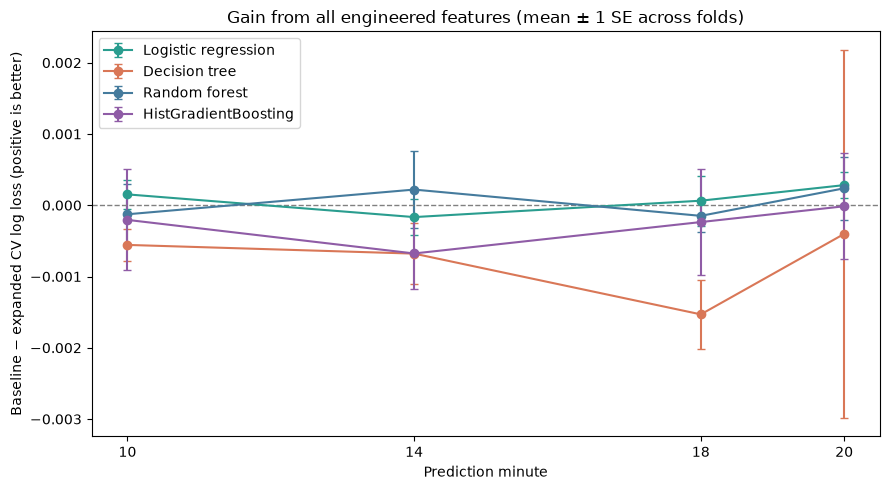

In [9]:
gain_rows = []
for (model_name, minute), part in comparison_by_minute.groupby(["model", "minute"]):
    baseline_rows = part.loc[part["features"].eq("Notebook 01 features")]
    if baseline_rows.empty:
        continue
    baseline = baseline_rows.iloc[0]
    for _, candidate in part.loc[~part["features"].eq("Notebook 01 features")].iterrows():
        ll = np.asarray(baseline["fold_log_loss"], dtype=float) - np.asarray(candidate["fold_log_loss"], dtype=float)
        acc = 100 * (np.asarray(candidate["fold_accuracy"], dtype=float)
                     - np.asarray(baseline["fold_accuracy"], dtype=float))
        assert len(ll) == len(acc) == cv.get_n_splits()
        gain_rows.append({
            "model": model_name, "minute": int(minute), "features": candidate["features"],
            "log_loss_reduction": ll.mean(),
            "log_loss_se": ll.std(ddof=1) / np.sqrt(len(ll)),
            "accuracy_gain_pp": acc.mean(),
            "accuracy_se_pp": acc.std(ddof=1) / np.sqrt(len(acc)),
        })
paired_gain = pd.DataFrame(gain_rows)
paired_gain.to_csv(report_dir / "ensemble_paired_gain.csv", index=False)
display(paired_gain.round(5))

fig, ax = plt.subplots(figsize=(9, 5))
for model_name, color in model_colors.items():
    # The default expanded set is All engineered; at minute 10 full ablation uses + objective.
    part = paired_gain.loc[
        paired_gain["model"].eq(model_name)
        & (paired_gain["features"].eq("All engineered")
           | (paired_gain["minute"].eq(10) & paired_gain["features"].eq("+ objective")))
    ].sort_values("minute")
    if not part.empty:
        ax.errorbar(part["minute"], part["log_loss_reduction"], yerr=part["log_loss_se"],
                    marker="o", capsize=3, color=color, label=model_name)
ax.axhline(0, color="gray", linestyle="--", linewidth=1)
ax.set_xticks(sorted(minute_frames))
ax.set_xlabel("Prediction minute")
ax.set_ylabel("Baseline − expanded CV log loss (positive is better)")
ax.set_title("Gain from all engineered features (mean ± 1 SE across folds)")
ax.legend()
fig.tight_layout()
fig.savefig(figure_dir / "ensemble_feature_gain.png", dpi=180, bbox_inches="tight")
plt.show()

## 7. Record candidate configurations for final evaluation

For each minute and ensemble family, select the feature set and hyperparameters with the lowest CV log loss. The exported specification includes the complete feature order and constructor parameters; final evaluation must refit it on all eligible training matches. No test evaluation takes place here.

Review the search CSVs before freezing the final choices. If a result lies at a grid boundary and a wider search is justified, do that using training CV now. Keep differences in feature count, interpretability, and fold variation in mind when gains are small.

In [10]:
ensemble_only = ensemble_by_minute.loc[ensemble_by_minute["model"].isin(MODEL_SPECS)].copy()
candidates = (ensemble_only.sort_values(["log_loss", "n_features", "model", "features"])
              .groupby(["minute", "model"], sort=True).head(1)
              .sort_values(["minute", "model"]).reset_index(drop=True))
write_results(candidates, report_dir / "ensemble_candidates.csv")
display(candidates[["minute", "model", "features", "n_features"] + METRIC_COLS + ["params"]].round(4))

candidate_specs = []
for _, row in candidates.iterrows():
    base_model = MODEL_SPECS[row["model"]][0]
    params = {**base_model.get_params(), **row["params"]}
    candidate_specs.append({
        "minute": int(row["minute"]), "model": row["model"],
        "estimator": f"{type(base_model).__module__}.{type(base_model).__name__}",
        "constructor": type(base_model).__name__,
        "params": params, "feature_set": row["features"],
        "feature_columns": row["feature_columns"], "threshold": 0.5,
        "train_matches": int(row["train_matches"]),
        "selection_metric": "minimum training CV log_loss", "cv_log_loss": float(row["log_loss"]),
        "fingerprint": row["fingerprint"],
    })
spec_path = report_dir / "ensemble_candidate_specs.json"
spec_path.write_text(json.dumps(
    {"provenance": PROVENANCE, "full_ablation": FULL_ABLATION,
     "random_forest_grid": RF_GRID, "hist_gradient_boosting_grid": HGB_GRID,
     "candidates": candidate_specs}, indent=2, default=json_default, allow_nan=False,
) + "\n")

assert len(candidates) == 2 * len(minute_frames)
assert len(ensemble_by_minute) == sum(1 + 2 * len(training_data_for(t)[1]) for t in minute_frames)
print("Saved candidate specifications:", spec_path)
print("Completed training CV. Held-out test evaluation is the next stage after final model choices.")

,minute,model,features,n_features,accuracy,accuracy_sd,roc_auc,log_loss,brier,params
0,10,HistGradientBoosting,Notebook 01 features,56,0.7217,0.0048,0.7991,0.5429,0.1829,"{'l2_regularization': 1.0, 'learning_rate': 0...."
1,10,Random forest,Notebook 01 features,56,0.7200,0.0058,0.8006,0.5410,0.1822,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."
2,14,HistGradientBoosting,Notebook 01 features,58,0.7698,0.0091,0.8529,0.4747,0.1566,"{'l2_regularization': 1.0, 'learning_rate': 0...."
3,14,Random forest,All engineered,80,0.7682,0.0089,0.8537,0.4733,0.1561,"{'max_depth': None, 'max_features': 'sqrt', 'm..."
4,18,HistGradientBoosting,Notebook 01 features,58,0.7954,0.0029,0.8824,0.4294,0.1395,"{'l2_regularization': 1.0, 'learning_rate': 0...."
5,18,Random forest,Notebook 01 features,58,0.7960,0.0045,0.8832,0.4275,0.1389,"{'max_depth': 8, 'max_features': 0.5, 'min_sam..."
6,20,HistGradientBoosting,Notebook 01 features,58,0.8074,0.0057,0.8931,0.4117,0.1327,"{'l2_regularization': 1.0, 'learning_rate': 0...."
7,20,Random forest,All engineered,80,0.8068,0.0050,0.8941,0.4097,0.1322,"{'max_depth': None, 'max_features': 'sqrt', 'm..."


Saved candidate specifications: /Users/home/Desktop/UT/26 Fall/CS 363M/CS-363M-ML-Project/reports/ensemble_candidate_specs.json
Completed training CV. Held-out test evaluation is the next stage after final model choices.


## 8. Findings

All results in this section use five-fold grouped cross-validation on training matches. Hyperparameters and feature sets were selected by minimum CV log loss. These are model-selection results; held-out test results are reported separately in notebook 05.

### 8.1 Minute-14 model comparison

The random forest using **All engineered** features has the lowest ensemble log loss, while HistGradientBoosting using **Notebook 01 features** has the highest ensemble accuracy.

| Model | Selected feature set | Accuracy | ROC AUC | Log loss | Brier score |
| --- | --- | ---: | ---: | ---: | ---: |
| Logistic regression | Four selected features | 77.10% | 0.8555 | 0.4705 | 0.1550 |
| Random forest | All engineered | 76.82% | 0.8537 | 0.4733 | 0.1561 |
| HistGradientBoosting | Notebook 01 features | 76.98% | 0.8529 | 0.4747 | 0.1566 |
| Decision tree | Four selected features | 76.50% | 0.8482 | 0.4816 | 0.1587 |

Isaac's four-feature logistic regression remains the leading minute-14 candidate under the tested configurations. Its inputs are `goldDiff`, `expDiff`, `dragonDiff`, and `killShare`. It has lower log loss and Brier score and higher accuracy and AUC than either selected ensemble.

Both ensembles improve on the four-feature decision tree's log loss. However, the differences between LR and the ensembles are small, and these CV scores do not establish a statistically significant ranking. The four-feature list was also selected during training exploration, so its reused-CV score is not an independent performance estimate.

The forest's baseline-feature version reaches 76.97% accuracy, compared with 76.82% for its expanded version. Nevertheless, the expanded version has slightly lower log loss, 0.4733 versus 0.4735, so it is selected according to the criterion established before comparison.

### 8.2 Do the expanded features help?

At minute 14, the comparison uses **58 Notebook 01 features** versus **80 All engineered features**.

The paired fold comparisons show no consistent improvement in log loss from the expanded features:

- **Random forest:** At minute 14, expanded features reduce log loss by 0.000220, with a descriptive standard error of 0.000535. At minute 20, the reduction is 0.000237, with SE 0.000440. Both improvements are smaller than their standard errors. At minutes 10 and 18, expanded features slightly increase log loss.
- **HistGradientBoosting:** Expanded features slightly increase log loss at every minute. At minute 14, the increase is 0.000677, with SE 0.000497 for the paired difference, and accuracy decreases by approximately 0.17 percentage points.
- **Metric differences:** Accuracy and log loss do not always favor the same feature set. At minute 18, expanded features increase RF accuracy by approximately 0.29 percentage points while slightly worsening log loss. We retain log loss as the selection criterion throughout.

Under the tested grids, the additional objective and trajectory summaries therefore provide no clear evidence of a useful ensemble improvement beyond the original feature set. This is consistent with Isaac's earlier results: the current resource advantages already contain much of the available predictive information.

The paired standard errors describe variation across five folds. They are not an independent significance test because the folds overlap in training data and also supported hyperparameter selection.

### 8.3 Prediction time and eligible matches

The following table uses the lowest-log-loss feature set for each ensemble at each minute.

| Minute | Training matches | RF accuracy | RF log loss | HGB accuracy | HGB log loss |
| --- | ---: | ---: | ---: | ---: | ---: |
| 10 | 19,912 | 72.00% | 0.5410 | 72.17% | 0.5429 |
| 14 | 19,723 | 76.82% | 0.4733 | 76.98% | 0.4747 |
| 18 | 18,565 | 79.60% | 0.4275 | 79.54% | 0.4294 |
| 20 | 17,738 | 80.68% | 0.4097 | 80.74% | 0.4117 |

Both ensembles become more accurate and have lower log loss at later prediction times. However, the eligible cohort also changes: training matches decrease from 19,912 at minute 10 to 17,738 at minute 20 because earlier-ending games drop out. These comparisons therefore combine additional information with changes in the population being predicted.

In the matching-feature comparisons, logistic regression retains lower log loss than both ensembles at every prediction minute.

Minute 10 has no trajectory features. Its baseline and expanded sets contain 56 and 70 features, respectively. The expanded set corresponds to notebook 03's `+ objective` label. At minutes 14, 18, and 20, the two sets contain 58 and 80 features.

### 8.4 Selected ensemble configurations

The following configurations are selected for final refitting based on training CV. All models use `random_state=42`.

**Random forest**

| Minute | Feature set | n_estimators | max_depth | min_samples_leaf | max_features |
| --- | --- | ---: | --- | ---: | --- |
| 10 | Notebook 01 features | 400 | 8 | 25 | 0.5 |
| 14 | All engineered | 400 | None | 25 | sqrt |
| 18 | Notebook 01 features | 200 | 8 | 25 | 0.5 |
| 20 | All engineered | 400 | None | 25 | sqrt |

RF uses `n_jobs=1` within each model because the shared evaluation helpers parallelize the CV searches.

**HistGradientBoosting**

The selected settings at every minute share:

- `learning_rate=0.05`
- `max_iter=200`
- `max_leaf_nodes=15`
- `l2_regularization=1.0`
- `early_stopping=False`

The selected feature set and leaf minimum are:

| Minute | Feature set | min_samples_leaf |
| --- | --- | ---: |
| 10 | Notebook 01 features | 20 |
| 14 | Notebook 01 features | 20 |
| 18 | Notebook 01 features | 100 |
| 20 | Notebook 01 features | 20 |

Each ensemble/feature/minute combination searched 16 settings. No additional grid refinement was performed. Several selected values lie at grid boundaries, and HGB's iteration count was fixed at 200, so the conclusions apply to the tested configurations rather than every possible ensemble setting.

The complete constructor parameters, feature order, and data provenance are saved in `reports/ensemble_candidate_specs.json`.

### 8.5 Final-evaluation handoff

The required ensemble training experiments are complete. Carry the selected RF/HGB configurations forward alongside Isaac's LR/DT choices.

Before inspecting held-out performance, freeze each model's feature set, parameters, preprocessing, and classification threshold. Refit on all eligible training matches and evaluate the frozen models on the reserved test matches in one final stage.

Save the predicted probabilities and use them for the final comparison table, ROC curves, confusion matrices, calibration curves, and error analysis. Keep model choices fixed after inspecting test results.

The main result files are:

- `reports/ensemble_minute14_comparison.csv`
- `reports/ensemble_by_minute.csv`
- `reports/ensemble_all_models_by_minute.csv`
- `reports/ensemble_paired_gain.csv`
- `reports/ensemble_candidates.csv`
- `reports/ensemble_candidate_specs.json`

Search caches and grid results are in `reports/ensemble_searches/`; figures are in `reports/figures/ensemble_*.png`.